In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score,
roc_auc_score,
average_precision_score,
classification_report,
confusion_matrix,
ConfusionMatrixDisplay,
RocCurveDisplay,
PrecisionRecallDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv(
r"C:\Users\gmsat\OneDrive\DOC\OneDrive\Desktop\vaishu\credit_card_fraud_detection\creditcard.csv"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
print(df.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [7]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (284807, 31)


In [8]:
print("Column names:")
print(df.columns)


Column names:
Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')


In [9]:
print("Data types:")
print(df.dtypes)

Data types:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object


In [10]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [11]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 1081


In [12]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (283726, 31)


In [13]:
print("Class distribution:")
print(df["Class"].value_counts())

Class distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [14]:
class_percentage = df["Class"].value_counts(normalize=True) * 100

print("Class percentage:")
print(class_percentage)

Class percentage:
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


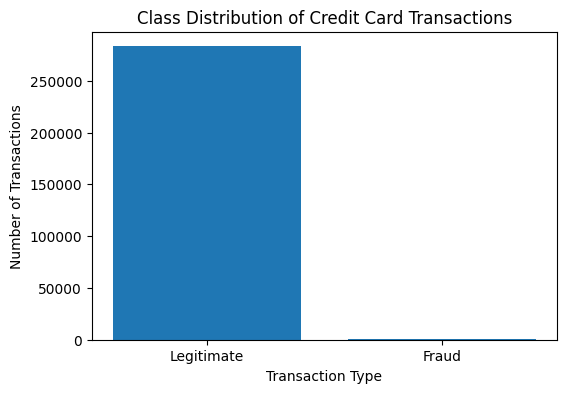

In [15]:
class_counts = df["Class"].value_counts()

plt.figure(figsize=(6, 4))

plt.bar(
["Legitimate", "Fraud"],
[class_counts[0], class_counts[1]]
)

plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.title("Class Distribution of Credit Card Transactions")

plt.show()

In [16]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (283726, 30)
Target shape: (283726,)


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.20,
random_state=42,
stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (226980, 30)
Testing data: (56746, 30)


In [18]:
logistic_model = Pipeline([
("scaler", StandardScaler()),
("model", LogisticRegression(
max_iter=1000,
class_weight="balanced",
solver="liblinear",
random_state=42
))
])

print("Logistic Regression model created!")

Logistic Regression model created!


In [20]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [21]:
y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression predictions completed!")

Logistic Regression predictions completed!


In [22]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)
pr_auc_lr = average_precision_score(y_test, y_prob_lr)

print("\nLOGISTIC REGRESSION RESULTS")
print("---------------------------")
print("Accuracy :", accuracy_lr)
print("Precision:", precision_lr)
print("Recall :", recall_lr)
print("F1 Score :", f1_lr)
print("ROC-AUC :", roc_auc_lr)
print("PR-AUC :", pr_auc_lr)


LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy : 0.9753286575265216
Precision: 0.05642420122365738
Recall : 0.8736842105263158
F1 Score : 0.10600255427841634
ROC-AUC : 0.9656552724948415
PR-AUC : 0.6736847981553121


In [23]:
print("\nLogistic Regression Classification Report")
print("------------------------------------------")

print(
classification_report(
y_test,
y_pred_lr,
target_names=["Legitimate", "Fraud"]
)
)


Logistic Regression Classification Report
------------------------------------------
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56651
       Fraud       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



Logistic Regression Confusion Matrix:
[[55263  1388]
 [   12    83]]


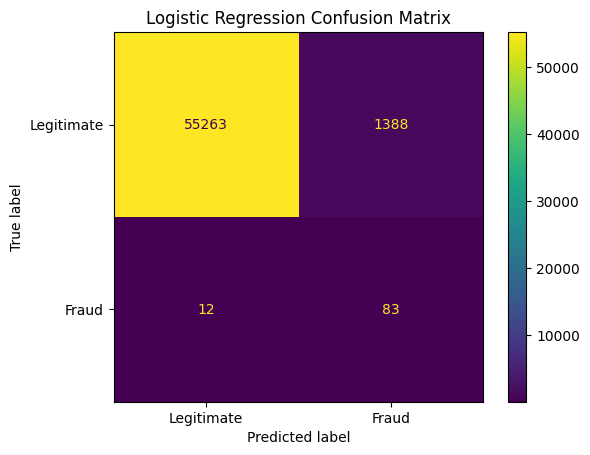

In [24]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

print("Logistic Regression Confusion Matrix:")
print(cm_lr)

ConfusionMatrixDisplay(
confusion_matrix=cm_lr,
display_labels=["Legitimate", "Fraud"]
).plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [25]:
random_forest_model = RandomForestClassifier(
n_estimators=80,
max_depth=14,
min_samples_leaf=2,
class_weight="balanced",
n_jobs=-1,
random_state=42
)

print("Random Forest model created!")

Random Forest model created!


In [26]:
train_data = X_train.copy()

train_data["Class"] = y_train.values

fraud_data = train_data[
train_data["Class"] == 1
]

normal_data = train_data[
train_data["Class"] == 0
]

In [27]:
normal_sample = normal_data.sample(
n=min(
len(normal_data),
len(fraud_data) * 5
),
random_state=42
)

balanced_train = pd.concat(
[fraud_data, normal_sample]
)

In [28]:
balanced_train = balanced_train.sample(
frac=1,
random_state=42
)

X_train_rf = balanced_train.drop(
"Class",
axis=1
)

y_train_rf = balanced_train["Class"]

print("Random Forest training data:", X_train_rf.shape)

print(
"Fraud transactions:",
sum(y_train_rf == 1)
)

print(
"Legitimate transactions:",
sum(y_train_rf == 0)
)

Random Forest training data: (2268, 30)
Fraud transactions: 378
Legitimate transactions: 1890


In [29]:
random_forest_model.fit(
X_train_rf,
y_train_rf
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [30]:
y_pred_rf = random_forest_model.predict(X_test)

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions completed!")

Random Forest predictions completed!


In [31]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
pr_auc_rf = average_precision_score(y_test, y_prob_rf)

print("\nRANDOM FOREST RESULTS")
print("---------------------")
print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall :", recall_rf)
print("F1 Score :", f1_rf)
print("ROC-AUC :", roc_auc_rf)
print("PR-AUC :", pr_auc_rf)


RANDOM FOREST RESULTS
---------------------
Accuracy : 0.9944313255559863
Precision: 0.20844327176781002
Recall : 0.8315789473684211
F1 Score : 0.3333333333333333
ROC-AUC : 0.9759195034416636
PR-AUC : 0.7057868185050508


In [32]:
print("\nRandom Forest Classification Report")
print("------------------------------------")

print(
classification_report(
y_test,
y_pred_rf,
target_names=["Legitimate", "Fraud"]
)
)


Random Forest Classification Report
------------------------------------
              precision    recall  f1-score   support

  Legitimate       1.00      0.99      1.00     56651
       Fraud       0.21      0.83      0.33        95

    accuracy                           0.99     56746
   macro avg       0.60      0.91      0.67     56746
weighted avg       1.00      0.99      1.00     56746



Random Forest Confusion Matrix:
[[56351   300]
 [   16    79]]


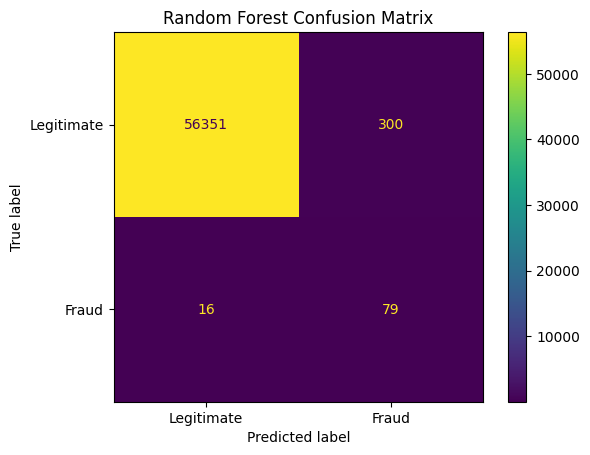

In [33]:
cm_rf = confusion_matrix(
y_test,
y_pred_rf
)

print("Random Forest Confusion Matrix:")
print(cm_rf)

ConfusionMatrixDisplay(
confusion_matrix=cm_rf,
display_labels=["Legitimate", "Fraud"]
).plot()

plt.title("Random Forest Confusion Matrix")
plt.show()

In [34]:
comparison = pd.DataFrame({
"Model": [
"Logistic Regression",
"Random Forest"
],
"Accuracy": [
accuracy_lr,
accuracy_rf
],
"Precision": [
precision_lr,
precision_rf
],
"Recall": [
recall_lr,
recall_rf
],
"F1 Score": [
f1_lr,
f1_rf
],
"ROC-AUC": [
roc_auc_lr,
roc_auc_rf
],
"PR-AUC": [
pr_auc_lr,
pr_auc_rf
]
})

print("\nMODEL COMPARISON")
print("================")

print(comparison)


MODEL COMPARISON
                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC  \
0  Logistic Regression  0.975329   0.056424  0.873684  0.106003  0.965655   
1        Random Forest  0.994431   0.208443  0.831579  0.333333  0.975920   

     PR-AUC  
0  0.673685  
1  0.705787  


<Figure size 800x600 with 0 Axes>

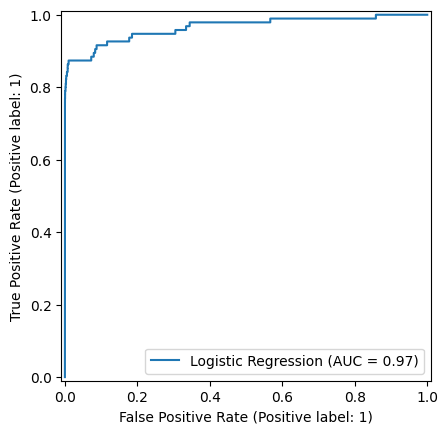

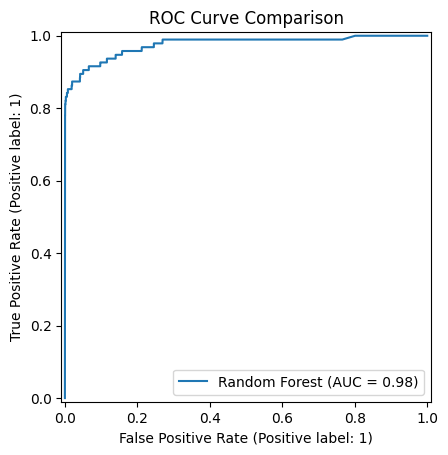

In [35]:
plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
y_test,
y_prob_lr,
name="Logistic Regression"
)

RocCurveDisplay.from_predictions(
y_test,
y_prob_rf,
name="Random Forest"
)

plt.title("ROC Curve Comparison")

plt.show()

<Figure size 800x600 with 0 Axes>

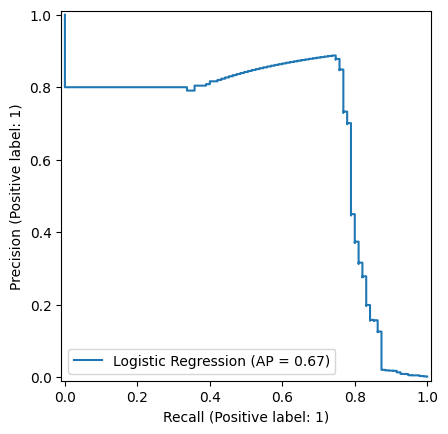

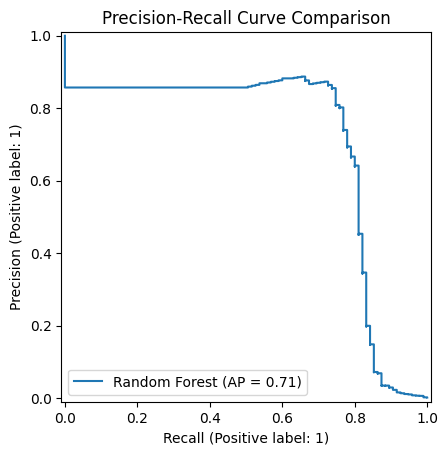

In [36]:
plt.figure(figsize=(8, 6))

PrecisionRecallDisplay.from_predictions(
y_test,
y_prob_lr,
name="Logistic Regression"
)

PrecisionRecallDisplay.from_predictions(
y_test,
y_prob_rf,
name="Random Forest"
)

plt.title("Precision-Recall Curve Comparison")

plt.show()

In [37]:
feature_importance = pd.Series(
random_forest_model.feature_importances_,
index=X_train_rf.columns
)

feature_importance = feature_importance.sort_values(
ascending=False
)

print("\nTop 10 Important Features:")
print(feature_importance.head(10))


Top 10 Important Features:
V14    0.208587
V10    0.126586
V4     0.109438
V12    0.092456
V17    0.081705
V3     0.072742
V16    0.051463
V11    0.045301
V2     0.032029
V7     0.018165
dtype: float64


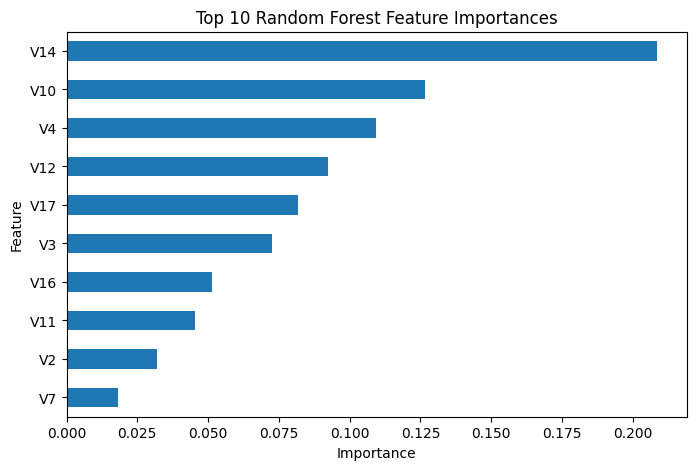

In [38]:
plt.figure(figsize=(8, 5))

feature_importance.head(10).sort_values().plot(
kind="barh"
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Random Forest Feature Importances")

plt.show()

In [40]:
print("\nFINAL MODEL COMPARISON")
print("======================")

if f1_rf > f1_lr:
    print("Random Forest performed better based on F1 Score.")
else:
    print("Logistic Regression performed better based on F1 Score.")

if recall_rf > recall_lr:
    print("Random Forest detected more fraud transactions.")
else:
    print("Logistic Regression detected more fraud transactions.")

print("\nProject completed successfully!")


FINAL MODEL COMPARISON
Random Forest performed better based on F1 Score.
Logistic Regression detected more fraud transactions.

Project completed successfully!
